# Resolution Matrix

Let the following define the forward problem : $$\mathbf y = \mathbf{Ls}$$ Where $\mathbf y$ is the M/EEG data, $\mathbf s$ are the source activity and $\mathbf L$ is the lead field matrix. <br><br>
If the inverse problem is linear we can define a linear estimator matrix $\mathbf G$ as: $$\mathbf{\hat s} = \mathbf{Gy}$$
<br><br>
From the above equations follows that $$\mathbf{\hat s} = \mathbf{Gy} = \mathbf{GLs} = \mathbf{Rs}$$ $\mathbf R$ is called the "resolution matrix". The resolution matrix contains a lot of information about the spatial resoluion of linear estimators, by means of their point-spread and cross-talk functions (PSFs and CTFs). <br><br>

In this notebook, we will compute the resolution matrix for various methods and compare their point-spread function as well as their cross-talk functions to evaluate their performance.

## 📦 Imports

In [26]:
import mindmap as mm
import mne

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- fwd: Forward solution
- eeg.info: EEG informations
- noise_cov: EEG noise covariance matrix

In [27]:
################ Parameters ##################
fconfig = "../../papers/simf/configuration.yml"
sub     = 1
samp    = 1     # session to sample
##############################################

reader = mm.io.dataset_reader(fconfig)
data   = reader(sub, "eeg", "fwd", sample=samp)

# Identity matrix for noise covariance matrix
noise_cov = mne.make_ad_hoc_cov(data["eeg"].info, std={"eeg":1})

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- fwd
- eeg
Missing objects:


## ⚙️ Make Inverse

In [28]:
# set average reference
data["eeg"].set_eeg_reference(ref_channels="average", projection=True, verbose="warning")

# solve inverse problem
inverse_operator = mne.minimum_norm.make_inverse_operator(
    info      = data["eeg"].info,
    forward   = data["fwd"],
    noise_cov = noise_cov,
    fixed     = True,
    depth     = 0,
    verbose   = "warning",
)

## ⚙️ Resolution Matrix

#### Point spread function
`psf`: A point spread function (PSF) characterizes how an imaging system transforms an ideal point source into a spatially distributed signal, effectively describing the system's blurring behavior. In this context, column $i$ of the resolution matrix represents the point spread associated with dipole $i$.

#### Cross talk function
`ctf`: The cross talk function (CTF) for a given source location describes how activity at other source locations can influence the estimate at that location. In other words, it quantifies the degree of "contamination" from surrounding sources. The $i$-th row of the resolution matrix corresponds to the CTF for location $i$.

#### Metrics
- `peak_err`: Peak localization error (PLE), Euclidean distance between peak and true source location. 
- `cog_err`: Centre-of-gravity localisation error (CoG), Euclidean distance between CoG and true source location.
- `sd_ext`: Spatial deviation.
- `maxrad_ext`: Maximum radius to 50% of max amplitude.
- `peak_amp`: Ratio between absolute maximum amplitudes of peaks per location and maximum peak across locations.
- `sum_amp`: Ratio between sums of absolute amplitudes.

In [29]:
# fix dipole orientation
forward = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")

# compute resolution matrix
resolution_matrix = mne.minimum_norm.make_inverse_resolution_matrix(
    forward          = forward, 
    inverse_operator = inverse_operator, 
    method           = "sLORETA", 
    lambda2          = 0.01, 
    verbose          = "warning",
)



# compute resolution metrics 
resolution_metrics = {"psf":{}, "ctf":{}} 
metrics            = ["peak_err", "cog_err", "sd_ext", "maxrad_ext", "peak_amp", "sum_amp"]

for f in resolution_metrics.keys():
    for m in metrics:
        resolution_metrics[f][m] = mne.minimum_norm.resolution_metrics(
            resmat   = resolution_matrix,
            src      = inverse_operator["src"],
            function = f,
            metric   = m,
            verbose  = "warning",
        )

📊 **Point spread and cross talk functions**

- `func`: type of fonction ("psf" or "ctf")

In [7]:
########### Parameters ###########
func = "ctf"
##################################

if func == "psf":
    rm = resolution_matrix.copy()
elif func == "ctf":
    rm = resolution_matrix.T.copy()
else:
    raise ValueError(f"Unknown function name: '{func}'")

mm.viz.plot_dipole_function(inverse_operator["src"], rm).show()

Widget(value='<iframe src="http://localhost:37257/index.html?ui=P_0x7536c4212bd0_2&reconnect=auto" class="pyvi…

📊 **Function metrics**

- `func`: type of function ("psf" or "ctf")
- `metric`: type of metric ("peak_err", "cog_err", "sd_ext", "maxrad_ext", "peak_amp", "sum_amp")

In [17]:
############# Parameters ##############
func = "psf"
metric = "peak_amp"
#######################################

signals = resolution_metrics[func][metric].data.squeeze()
mm.viz.plot_brain(inverse_operator["src"], signals, title=f"function: {func}, metric: {metric}").show()

Widget(value='<iframe src="http://localhost:37257/index.html?ui=P_0x7535207f6a90_10&reconnect=auto" class="pyv…

In [ ]:
from abc import ABC, abstractmethod
import mne
import numpy as np

import pyxu.abc as pxa
import pyxu.operator as pxo
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

class Inverse_Operator(ABC):
    # m defines the number of sensors while n defines the number of sources
    info: mne._fiff.meas_info.Info      # Sensor info object

    # Core data
    L: mne.Forward                      # Leadfield matrix (a.k.a forward solution) (m,n)
    Nc: mne.cov.Covariance              # Noise Covariance matrix (sensor noise) (m,m)
    Pm: np.ndarray                      # Prior Mixing matrix (n,n)
    Bt: np.ndarray                      # Basis transformation matrix (a.k.a component-wise extraction matrix) (n,n)

    # whitening
    W: np.ndarray                       # Whitener (m,m)
    C: np.ndarray                       # Colorer (m,m)

    # depth prior
    Dp: np.ndarray                      # Depth Prior matrix
    exp: float                          # Exponent used for depth weighting

    # verbosity (global attribute)
    verbose = "warning"

    def __init__(
        self, 
        info, 
        leadfield, 
        noise_cov       = None, 
        prior_mixing    = None, 
        basis_transform = None, 
        lambda_         = 0.01, 
        whiten          = True, 
        depth           = 0.8,
    ):
        self.info = info

        # core data
        self.L  = mne.convert_forward_solution(leadfield, force_fixed=True, verbose="warning")  # we always work with fixed orientation
        
        self.Nc  = noise_cov       if noise_cov is not None       else mne.make_ad_hoc_cov(data["eeg"].info, std={"eeg":1})
        self.Pm  = prior_mixing    if prior_mixing is not None    else np.eye(self.L["nsource"])
        self.Bt  = basis_transform if basis_transform is not None else np.eye(self.L["nsource"])
        self.lam = lambda_

        # whitening
        if whiten:
            self.compute_whitener()
        else:
            self.W = np.eye(leadfield["nchan"])
            self.C = np.eye(leadfield["nchan"])

        # depth prior
        self.compute_depth_prior(exponent=depth)

    @abstractmethod
    def __call__():
        pass

    def compute_whitener(self):
        """
        Computes whitener and colorer.

        New attributes
        ----------
        W: np.ndarray (m,m)
            Whitener. Let UDU.T be the eigdendecomposition of Nc. Then W = D^(-1/2)U.T

        C: np.ndarray (m,m)
            Colorer. C = W^(-1)

        whiten_method: str
            Method used for whitening.
        """

        self.W, _, self.C = mne.cov.compute_whitener(
            noise_cov      = self.Nc,
            info           = self.info,
            picks          = self.select_channels(),
            pca            = "white",
            return_colorer = True,
            verbose        = self.verbose,
        )



    def scaling(self, Nave):
        pass

    def compute_depth_prior(self, exponent=0.8, limit=10.0):
        """
        Computes the depth priors. The depth prior is a diagonal matrix whose elements serve to weight sources according to their depth, 
        as measured by the columns of the leadfield matrix. The purpose is to counteract the minimum estimate bias toward superficial sources.

        Parameters
        ----------
        exponent: float [0-1]
            Exponent for depth weighting.

        New attributes
        ----------
        Dp: np.ndarray (n,n)
            Depth prior matrix.

        exp: float [0-1]
            Exponent used for depth weighting.
        """
        self.exp = exponent

        self.Dp = mne.forward.compute_depth_prior(
            forward   = self.L,
            info      = self.info,
            exp       = exponent,
            limit     = limit,
            noise_cov = self.Nc,
            verbose   = self.verbose,
        )

    def select_channels(self):
        """
        Select channels available in both info and Nc.
        """
        info_names = set(self.info["ch_names"])
        info_bads  = set(self.info["bads"])

        Nc_names = set(self.Nc["names"])
        Nc_bads  = set(self.Nc["bads"])

        ch_names = info_names & Nc_names
        bads     = info_bads | Nc_bads

        ch_names -= bads

        return list(ch_names)
        


class CSET(Inverse_Operator):

    def __init__(
        self, 
        info, 
        leadfield,
        basis_transform,    # required 
        noise_cov       = None, 
        lambda_         = 0.01, 
        whiten          = True, 
        depth           = 0,
    ):
        super.__init__(
            info            = info,
            leadfield       = leadfield,
            noise_cov       = noise_cov,
            basis_transform = basis_transform,
            mixing_matrix   = None,             # no mixing possible (yet)
            lambda_         = lambda_,
            whiten          = whiten,
            depth           = depth,
        )

    def __call__(self, data):
        """
        Applies the Connectome Spectrum Electromagnetic Tomography (CSET) source reconstruction method. 

        Parameter
        ---------
        data: mne.Evoked
            Sensor data to project to source space.

        Return
        ------
        stc: mne.SourceEstimate 
            Source Time Currents.
        """
        n = self.L["nsource"]   # number of sources
        t = len(data.times)     # number of time points

        Y = data.data
        L = self.L["sol"]["data"].astype("float64")

        # whiten leadfield and data
        L = self.W @ L 
        Y = self.W @ Y

        # apply depth prior
        L = L @ np.diag(self.Dp)

        # component wise transformation
        L = L @ self.Bt

        # -----------------------
        # Solve CSET using pyxu
        # -----------------------

        # Instanciate pyxu objects
        L     = pxa.LinOp.from_array(L)
        prior = self.lam * pxo.L1Norm(dim_shape=n)
        sol   = np.zeros((n, t))                        # inverse solution
        sc    = pxst.MaxIter(1000)                      # stoping criterion

        for tp in range(t):
            y     = Y[:,tp]
            s_hat = np.random.random(n)*10**(-9)

            likelihood = pxo.SquaredL2Norm(dim_shape=L.codim_shape).argshift(-y)*L
            likelihood.diff_lipschitz = likelihood.estimate_diff_lipschitz()

            solver = PGD(f=likelihood, g=prior, show_progress=False)

            solver.fit(x0=s_hat, stop_crit=sc)

            s_hat = solver.solution().squeeze()
            sol[:,tp] = (self.Bt @ s_hat)

        # store result in MNE object
        vertices = [self.L["src"][0]["vertno"], self.L["src"][1]["vertno"]]
        stc      = mne.SourceEstimate(sol, vertices, tmin=data.times[0], tstep=1/data.info["sfreq"])

        return stc


class wCSET(Inverse_Operator):

    def __init__(
        self, 
        info, 
        leadfield, 
        mixing_matrix,      # required
        basis_transform,    # required
        noise_cov       = None, 
        lambda_         = 0.01, 
        whiten          = True, 
        depth           = 0,
    ):
        super.__init__(
            info            = info,
            leadfield       = leadfield,
            noise_cov       = noise_cov,
            basis_transform = basis_transform,
            mixing_matrix   = mixing_matrix,
            lambda_         = lambda_,
            whiten          = whiten,
            depth           = depth,
        )


    def __call__(self, data):
        """
        Applies the weighted Connectome Spectrum Electromagnetic Tomography (wCSET) source reconstruction method. 

        Parameters
        ----------
        data: mne.Evoked 
            Sensor data. 

        Return
        ------
        stc: mne.SourceEstimate 
            Source Time Currents.
        """
        Y = data.data

        # whiten data 
        Y = self.W @ Y

        # build kernel
        T = self.build_kernel()

        # compute solution
        # - Solution is computed in the graph spectrum space 
        # - Basis transform is used to revert back to dipole space
        sol = self.Bt @ T @ Y 

        # store result in MNE object
        vertices = [self.L["src"][0]["vertno"], self.L["src"][1]["vertno"]]
        stc      = mne.SourceEstimate(sol, vertices, tmin=data.tmin, tstep=1/data.info["sfreq"])

        return stc
        

    def build_kernel(self):
        """
        Computes the linear inverse operator (kernel).

        Attributes
        ----------
        L: mne.Forward 
            Leadfield (forward solution)
        
        W: np.ndarray 
            Whitener

        Dp: np.ndarray 
            Depth prior

        Bt: np.ndarray 
            Basis transform (a.k.a component wise extraction)

        Pm: np.ndarray 
            Prior mixing matrix

        lam: float
            Regularizer parameter.
        """
        n = self.L["nsource"]
        L = self.L["sol"]["data"].astype("float64") 

        # whiten
        L = self.W @ L 

        # depth prior
        L = L @ np.diag(self.Dp)

        # Component-wise transform
        L = L @ self.Bt 

        # kernel
        T = np.linalg.inv(L.T@L + self.lam @ self.Pm) @ L.T

        return T


# implement other inverse operators through MNE.

In [200]:
diag = 5*np.ones(len(data["eeg"].ch_names))

cov = mne.make_ad_hoc_cov(data["eeg"].info, std={"eeg":diag})

In [201]:
W, _ = mne.cov.compute_whitener(cov, data["eeg"].info)



    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 0.011 (2.2e-16 eps * 203 dim * 2.5e+11  max singular value)
    Estimated rank (eeg): 202
    EEG: rank 202 computed from 203 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
    Created the whitener using a noise covariance matrix with rank 202 (1 small eigenvalues omitted)


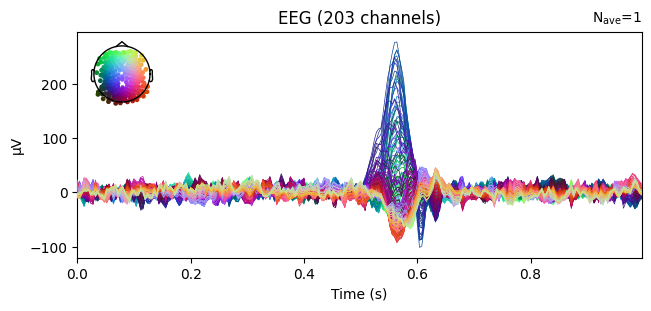

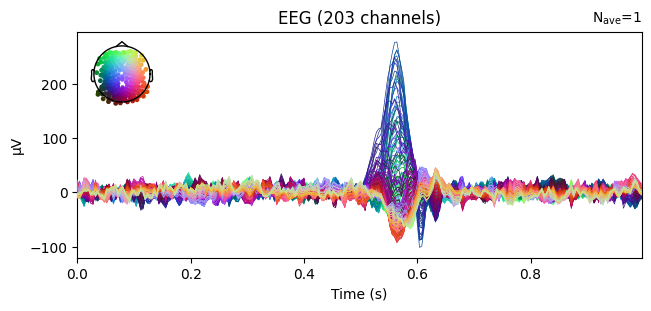

In [ ]:
baseline = [0.0, 0.4]

def compute_evoked_covariance(
    evoked, 
    tmin = None, 
    tmax = 0.0,
    scalings = dict(mag=1e15, grad=1e13, eeg=1e6),
):
    """
    Compute a surrogate of the noise covariance when only evoked is available.

    Parameter
    ---------
    evoked: mne.Evoked 
        Evoked sensor data.

    tmin: float
        First time point belonging to baseline (in [ms])

    tmax: float
        Last time point belonging to baseline (in [ms])
    """

    data = evoked.copy()
    data.crop(tmin=tmin, tmax=tmax)

In [205]:
1/5

0.2